In [347]:
import numpy as np
import math as mp
import pandas as pd

In [348]:
sigma = 5
beta = 1 /( 1.0 +0.01)
beta1 =1/( (1.0 +0.01* np.exp(30/(36.5*0.9)))) 
power = (1+2)/(-1-2)
W = 1

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_18932/2773425506.py:1: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  data=pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True, infer_datetime_format=True)
/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_18932/2773425506.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data=pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True, infer_datetime_format=True)


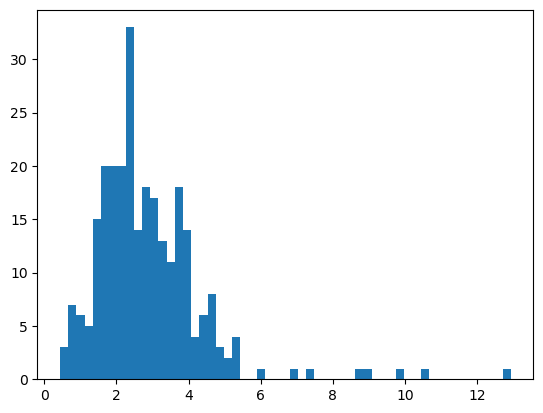

In [349]:
data=pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True, infer_datetime_format=True)
data_tau=(data['invtCogsRatio']* 36.5/(30*0.1))
import matplotlib.pyplot as plt
plt.hist(data_tau,bins = 55)
plt.show()

In [350]:
tau_diff = np.zeros(( 1000,1))
i = 0
for c in np.linspace(0, 0.99, 1000): 
    N = -(data_tau) - 1/np.log(beta*c) 
    tau1= -1/np.log(beta*c) - N
    tau1[tau1<0] = 0     
    tau2= -1/np.log(beta1*c) - N
    tau2[tau2<0] = 0    
    tau_diff[i] = np.mean(np.abs(tau1-tau2))
    i = i+1

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_18932/1678760125.py:4: RuntimeWarning: divide by zero encountered in log
  N = -(data_tau) - 1/np.log(beta*c)
/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_18932/1678760125.py:5: RuntimeWarning: divide by zero encountered in log
  tau1= -1/np.log(beta*c) - N
/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_18932/1678760125.py:7: RuntimeWarning: divide by zero encountered in log
  tau2= -1/np.log(beta1*c) - N


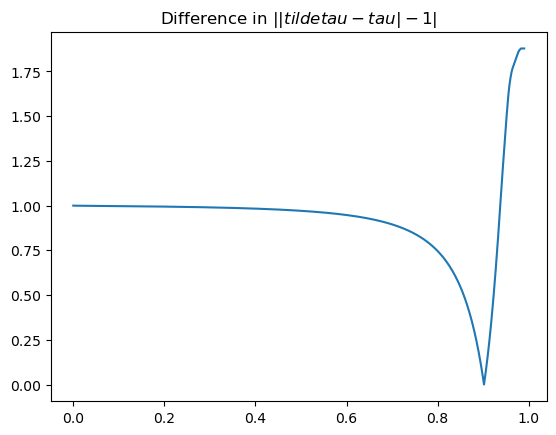

In [351]:
plt.plot(np.linspace(0, 0.99, 1000),np.abs(tau_diff-1))
plt.title('Difference in $||tildetau - tau| -1|$')

plt.show()

In [352]:
min_val = np.min(np.abs(tau_diff-1))
argmins = np.where(np.abs(tau_diff-1) == min_val)[0]

In [353]:
c_list = np.linspace(0, 0.99, 1000)
c= np.min(c_list[argmins])

In [354]:
N=-data_tau - 1/np.log(beta*c) 
tau= -1/np.log(beta*c) - N
tau[tau<0] = 0  
tau_floor = np.floor(tau)
tau_ceil = np.ceil(tau)
tprod_ceil=  (beta*c)**tau_ceil * (tau_ceil + N)
tprod_floor=  (beta*c)**tau_floor * (tau_floor + N)

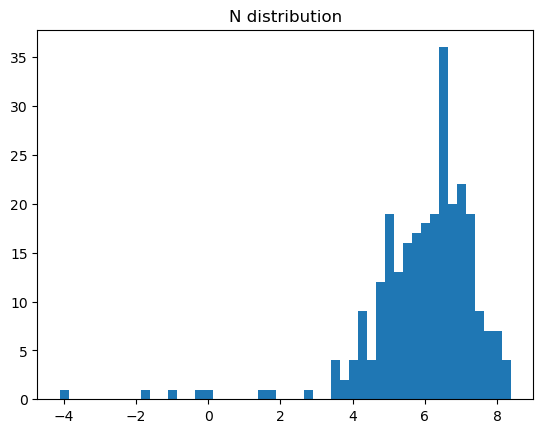

In [355]:
plt.hist(N, bins=50)
plt.title('N distribution')
plt.show()

In [356]:
tau[(tprod_ceil-tprod_floor)>0] = tau_ceil[(tprod_ceil-tprod_floor)>0]
tau[(tprod_ceil-tprod_floor)<0] = tau_floor[(tprod_ceil-tprod_floor)<0]
tau[tau<0] = 0  
tprod = (beta*c)**tau * (tau + N)

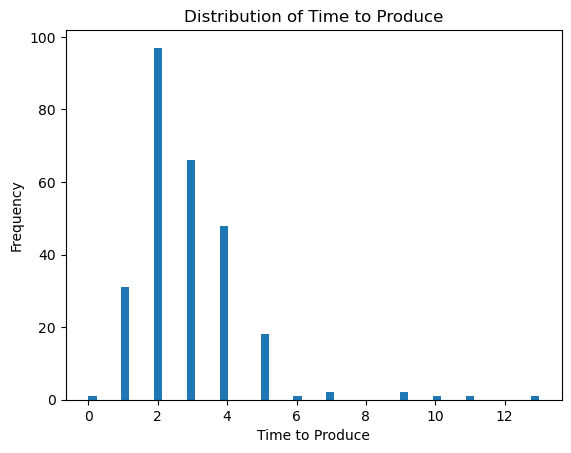

In [357]:
plt.hist(tau, bins = 55, alpha=1, label='tau_noise')
plt.xlabel('Time to Produce')
plt.ylabel('Frequency')
plt.title('Distribution of Time to Produce')
plt.show()

In [358]:

def generate_pattern_array_with_extra_rows(tau):
    # 1) Create the original n×n pattern
    n = len(tau)+ int(np.min(tau))
    m = int(np.max(tau)) + int(np.min(tau))

    mx = int(max(tau))
    missing_count = len(set(range(int(max(tau) )+ 1)) - set(tau))


    A = np.ones((m+2, n+missing_count), dtype=float)
    count = 0
    for i in range(1, m+2):
        for j in range(len(tau[tau == i-1])):
            A[i, n- i-j - count] = 0.997  # 0.9 shifts diagonally from right to left as we go down
        if len(tau[tau == i-1]) > 1:
            count += len(tau[tau == i-1])-1
    # 2) Create the two extra rows:
    #    (a) one row with 0.9 at the leftmost column,
    #    (b) one row of all ones.

    row_all_ones = np.ones(n+missing_count, dtype=float)
    A_extended = np.vstack([A,row_all_ones])
    A_extended = A_extended[:,0:n - int(np.min(tau))]

    return A_extended

In [359]:
tau1 = -1 / np.log(beta * c) - N
tau1[tau1 < 0] = 0
tau1_floor = np.floor(tau1)
tau1_ceil  = np.ceil(tau1)
tprod1_ceil  = (beta * c) ** tau1_ceil  * (tau1_ceil + N)
tprod1_floor = (beta * c) ** tau1_floor * (tau1_floor + N)

tau1[(tprod1_ceil - tprod1_floor) > 0] = tau1_ceil[(tprod1_ceil -
       tprod1_floor) > 0]
tau1[(tprod1_ceil - tprod1_floor) < 0] = tau1_floor[(tprod1_ceil -
tprod1_floor) < 0]
tau1[tau1 < 0] = 0
tprod1 = (beta * c) ** tau1 * (tau1 + N)

tau1 = tau1[::-1]
N1 = N[::-1]
tprod1 = np.array((beta * c) ** tau1 * (tau1 + N1))

A  = generate_pattern_array_with_extra_rows(tau1)
A_ones_like = np.ones(A.shape)
A_ones_like[1,:] =0.97
P0 = (np.sum(1 / (A_ones_like * tprod1) ** (1 - sigma), axis=1)) ** (1 / (1 -
        sigma))
P_original = P0
C_original = (P0)**power/P0[0]**power-1  # Consumption
C_padding_original = np.zeros(len(C_original) +1)
C_padding_original[1:] = C_original
pi_original = -  (C_padding_original[1:] - C_padding_original[:-1])

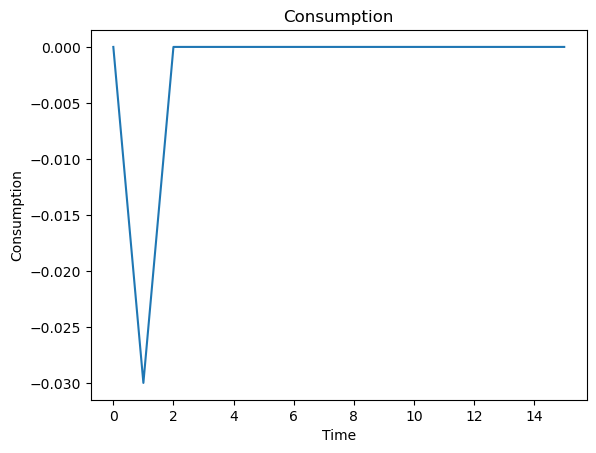

In [360]:
plt.plot(C_original)
plt.xlabel('Time')
plt.ylabel('Consumption')
plt.title('Consumption')
plt.show()

In [361]:
import numpy as np
import itertools

sequence_length = 5
r_choice = np.linspace(0, 0.0125, 6)  # 6 values from 0 to 0.0125 inclusive

# Generate all possible combinations (Cartesian product)
all_combinations = list(itertools.product(r_choice, repeat=sequence_length))

# Convert to NumPy array
big_array = np.array(all_combinations)

print(big_array.shape)  # Should be (6^6, 6) = (46656, 6)

# Assign to r_arrange
r_arrange = big_array
size = r_arrange.shape[0]

(7776, 5)


In [362]:
r_choice

array([0.    , 0.0025, 0.005 , 0.0075, 0.01  , 0.0125])

In [363]:
def output_fixed_ttb(r_seq, A_mat, tau_fixed, N_arr, c_param, sigma_param, power_param,
                     r_ss=0.01):
    """
    Fixed time-to-build output for an interest-rate path.

    Discount factor for a firm finishing at time j uses the product
        D[j, i] = prod_{s = j - tau_i + 1}^{j} beta_s
    so a change in r_t propagates to every cohort whose build window
    [j - tau_i + 1, j] contains t. Periods before time 0 use beta_ss.
    Reduces to (beta * c)^tau * (tau + N) when r_t is constant.
    """
    n_periods = A_mat.shape[0]
    beta_t = 1.0 / (1.0 + np.asarray(r_seq, dtype=float))
    beta_ss = 1.0 / (1.0 + r_ss)
    if len(beta_t) < n_periods:
        beta_t = np.concatenate([beta_t, np.full(n_periods - len(beta_t), beta_ss)])
    else:
        beta_t = beta_t[:n_periods]

    tau_f = np.asarray(tau_fixed, dtype=float)
    tau_i = tau_f.astype(int)
    N_f   = np.asarray(N_arr, dtype=float)
    tau_max = int(tau_i.max())

    # Prepend tau_max steady-state betas so j - tau_i + 1 can be negative safely.
    beta_ext = np.concatenate([np.full(tau_max, beta_ss), beta_t])              # (tau_max + n_periods,)
    log_cum  = np.concatenate([[0.0], np.cumsum(np.log(beta_ext))])             # (tau_max + n_periods + 1,)

    # Build-window product via prefix sums:
    #   log D[j, i] = log_cum[j + tau_max + 1] - log_cum[j + tau_max - tau_i + 1]
    end_idx   = np.arange(n_periods) + tau_max + 1                              # (n_periods,)
    start_idx = end_idx[:, None] - tau_i[None, :]                               # (n_periods, n_firms)
    log_disc  = log_cum[end_idx][:, None] - log_cum[start_idx]                  # (n_periods, n_firms)
    disc      = np.exp(log_disc)                                                # = prod of beta over build window

    base = (tau_f + N_f) * (c_param ** tau_f)                                   # (n_firms,)
    full = A_mat * disc * base[None, :]

    P0 = (np.sum(1.0 / full ** (1 - sigma_param), axis=1)) ** (1.0 / (1.0 - sigma_param))
    C  = P0 ** power_param / P0[0] ** power_param - 1.0
    C_pad = np.concatenate([[0.0], C])
    pi = -(C_pad[1:] - C_pad[:-1])
    return C, pi

In [364]:
from joblib import Parallel, delayed

A_fixed = generate_pattern_array_with_extra_rows(tau1)

# threads: each call is numpy-heavy and BLAS releases the GIL, so no pickling cost
results = Parallel(n_jobs=-1, prefer='threads', verbose=1)(
    delayed(output_fixed_ttb)(r_arrange[k], A_fixed, tau1, N1, c, sigma, power)
    for k in range(size)
)

C_all  = np.array([r[0] for r in results])
pi_all = np.array([r[1] for r in results])

print('C_all shape :', C_all.shape)
print('pi_all shape:', pi_all.shape)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 168 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 418 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 768 tasks      | elapsed:    0.3s
[Parallel(n_jobs=-1)]: Done 1218 tasks      | elapsed:    0.5s
[Parallel(n_jobs=-1)]: Done 1768 tasks      | elapsed:    0.7s
[Parallel(n_jobs=-1)]: Done 2418 tasks      | elapsed:    0.9s
[Parallel(n_jobs=-1)]: Done 3168 tasks      | elapsed:    1.2s
[Parallel(n_jobs=-1)]: Done 4018 tasks      | elapsed:    1.5s
[Parallel(n_jobs=-1)]: Done 4968 tasks      | elapsed:    1.9s
[Parallel(n_jobs=-1)]: Done 6018 tasks      | elapsed:    2.3s
[Parallel(n_jobs=-1)]: Done 7168 tasks      | elapsed:    2.7s


C_all shape : (7776, 16)
pi_all shape: (7776, 16)


[Parallel(n_jobs=-1)]: Done 7776 out of 7776 | elapsed:    3.0s finished


In [365]:
       for sigma in [5]:
           tau1 = -1 / np.log(beta * c) - N
           tau1[tau1 < 0] = 0
           tau1_floor = np.floor(tau1)
           tau1_ceil  = np.ceil(tau1)
           tprod1_ceil  = (beta * c) ** tau1_ceil  * (tau1_ceil + N)
           tprod1_floor = (beta * c) ** tau1_floor * (tau1_floor + N)

           tau1[(tprod1_ceil - tprod1_floor) > 0] = tau1_ceil[(tprod1_ceil -
       tprod1_floor) > 0]
           tau1[(tprod1_ceil - tprod1_floor) < 0] = tau1_floor[(tprod1_ceil -
       tprod1_floor) < 0]
           tau1[tau1 < 0] = 0
           tprod1 = (beta * c) ** tau1 * (tau1 + N)

           tau1 = tau1[::-1]
           N1 = N[::-1]
           tprod1 = np.array((beta * c) ** tau1 * (tau1 + N1))

           A  = generate_pattern_array_with_extra_rows(tau1)
           P0 = (np.sum(1 / (A * tprod1) ** (1 - sigma), axis=1)) ** (1 / (1 -
        sigma))
           C = (P0)**power/P0[0]**power-1  # Consumption
           C_padding = np.zeros(len(C) +1)
           C_padding[1:] = C
           pi = -  (C_padding[1:] - C_padding[:-1])  # Inflation

Best sequence index    : 6220
Sum of squared deviation: 2.6727206241654748e-06
Interest-rate sequence : [0.01 0.01 0.01 0.01 0.01]


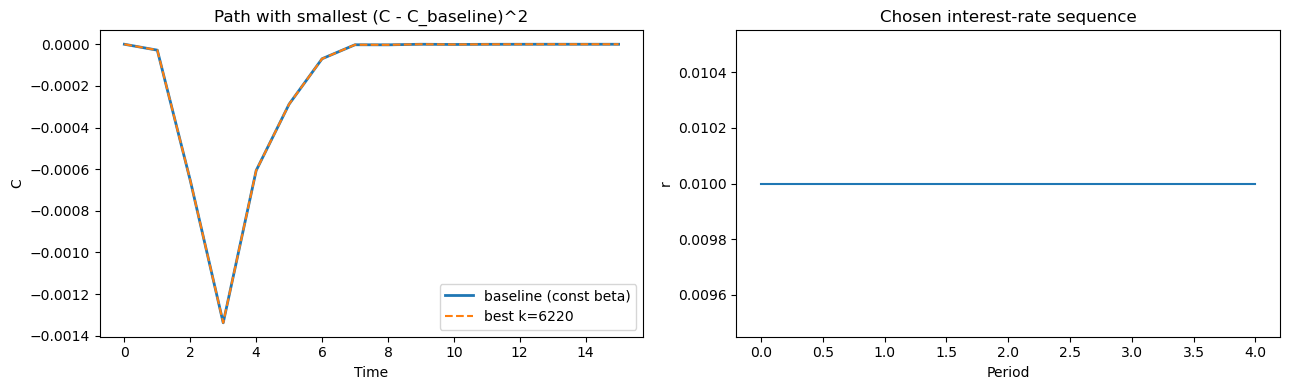

In [366]:
C_baseline = C  # steady-state (const-beta) consumption from cell 69f6b281

dev = np.sum((C_all) ** 2, axis=1)
best_k = int(np.argmin(dev))

print('Best sequence index    :', best_k)
print('Sum of squared deviation:', dev[best_k])
print('Interest-rate sequence :', r_arrange[best_k])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(C_baseline,     label='baseline (const beta)', linewidth=2)
axes[0].plot(C_all[best_k], '--', label=f'best k={best_k}')
axes[0].set_xlabel('Time'); axes[0].set_ylabel('C')
axes[0].set_title('Path with smallest (C - C_baseline)^2')
axes[0].legend()

axes[1].step(np.arange(len(r_arrange[best_k])), r_arrange[best_k], where='post')
axes[1].set_xlabel('Period'); axes[1].set_ylabel('r')
axes[1].set_title('Chosen interest-rate sequence')
plt.tight_layout()
plt.show()